In [3]:
import pandas as pd
import numpy as np

In [4]:
dataset=pd.read_csv("PrePlacement.csv")

In [4]:
dataset.isnull().sum()

sl_no             0
gender            0
ssc_p             0
ssc_b             0
hsc_p             0
hsc_b             0
hsc_s             0
degree_p          0
degree_t          0
workex            0
etest_p           0
specialisation    0
mba_p             0
status            0
salary            0
dtype: int64

In [5]:
#In this dataset there is no null or missing values

In [17]:
dataset

,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
0,1,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,Placed,270000.0
1,2,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,Placed,200000.0
2,3,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,Placed,250000.0
3,4,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,Not Placed,0.0
4,5,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,Placed,425000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
210,211,M,80.60,Others,82.00,Others,Commerce,77.60,Comm&Mgmt,No,91.0,Mkt&Fin,74.49,Placed,400000.0
211,212,M,58.00,Others,60.00,Others,Science,72.00,Sci&Tech,No,74.0,Mkt&Fin,53.62,Placed,275000.0
212,213,M,67.00,Others,67.00,Others,Commerce,73.00,Comm&Mgmt,Yes,59.0,Mkt&Fin,69.72,Placed,295000.0
213,214,F,74.00,Others,66.00,Others,Commerce,58.00,Comm&Mgmt,No,70.0,Mkt&HR,60.23,Placed,204000.0


In [19]:
#How many of them are not placed?
dataset["status"].value_counts()

status
Placed        148
Not Placed     67
Name: count, dtype: int64

In [ ]:
#67 students not placed so the salary is 0

In [20]:
dataset[dataset["status"] == "Not Placed"]["status"].value_counts()

status
Not Placed    67
Name: count, dtype: int64

What kind of relation between salary and mba_p

In [27]:
correlation = dataset['salary'].corr(dataset['mba_p'])

In [28]:
correlation

np.float64(0.14141713944325937)

In [ ]:
# here we get 14% correlation between mba and salary , its nearly zero correlation

Which specialization is getting minimum salary

In [30]:
dataset["salary"].min()

np.float64(0.0)

In [36]:
def quanqual(dataset):
   quan=[]
   qual=[]
   for columnName in dataset.columns:
     if(dataset[columnName].dtype=='str'):
        qual.append(columnName)
     else:
        quan.append(columnName)    
   return quan,qual
    


In [38]:
quan,qual=quanqual(dataset)

In [42]:
descriptive=pd.DataFrame(index=["Mean","Median","Mode","Q1:25%","Q2:50%",
                                   "Q3:75%","99%","Q4:100%","Min","Max"],columns=quan)
for columnName in quan:
            descriptive.loc["Mean",columnName]=dataset[columnName].mean()
            descriptive.loc["Median",columnName]=dataset[columnName].median()
            descriptive.loc["Mode",columnName]=dataset[columnName].mode()[0]
            descriptive.loc["Q1:25%",columnName]=dataset.describe()[columnName]["25%"]
            descriptive.loc["Q2:50%",columnName]=dataset.describe()[columnName]["50%"]
            descriptive.loc["Q3:75%",columnName]=dataset.describe()[columnName]["75%"]
            descriptive.loc["99%",columnName]=np.percentile(dataset[columnName],99)
            descriptive.loc["Q4:100%",columnName]=dataset.describe()[columnName]["max"] 
            descriptive.loc["Min",columnName]=dataset[columnName].min()
            descriptive.loc["Max",columnName]=dataset[columnName].max()

In [43]:
descriptive

,sl_no,ssc_p,hsc_p,degree_p,etest_p,mba_p,salary
Mean,108.0,67.303395,66.334744,66.358558,72.100558,62.278186,197615.116279
Median,108.0,67.0,65.0,66.0,71.0,62.0,240000.0
Mode,1,62.0,63.0,65.0,60.0,56.7,0.0
Q1:25%,54.5,60.6,60.9,61.0,60.0,57.945,0.0
Q2:50%,108.0,67.0,65.0,66.0,71.0,62.0,240000.0
Q3:75%,161.5,75.7,73.0,72.0,83.5,66.255,282500.0
99%,212.86,87.0,91.129,83.86,97.0,76.1142,629000.0
Q4:100%,215.0,89.4,91.15,88.5,98.0,77.89,706250.0
Min,1,40.89,42.75,50.0,50.0,51.21,0.0
Max,215,89.4,91.15,88.5,98.0,77.89,706250.0


In [44]:
min_salary_by_spec = dataset.groupby('specialisation')['salary'].min()

In [45]:
absolute_min_salary = min_salary_by_spec.min()
specializations_with_min_salary = min_salary_by_spec[min_salary_by_spec == absolute_min_salary]

In [46]:
specializations_with_min_salary

specialisation
Mkt&Fin    0.0
Mkt&HR     0.0
Name: salary, dtype: float64

In [52]:
min_salary=dataset["salary"].min()
result=dataset.loc[dataset["salary"]==min_salary,"specialisation"].unique()

In [53]:
result

<StringArray>
['Mkt&HR', 'Mkt&Fin']
Length: 2, dtype: str

In [60]:
count=dataset[dataset['salary']>500000]

In [61]:
count

,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
119,120,M,60.8,Central,68.40,Central,Commerce,64.6,Comm&Mgmt,Yes,82.66,Mkt&Fin,64.34,Placed,706250.0
150,151,M,71.0,Central,58.66,Central,Science,58.0,Sci&Tech,Yes,56.00,Mkt&Fin,61.30,Placed,690000.0
177,178,F,73.0,Central,91.15,Others,Commerce,79.0,Comm&Mgmt,Yes,89.00,Mkt&Fin,70.81,Placed,650000.0


In [62]:
totalcount=(dataset['salary']>500000).sum()

In [63]:
totalcount

np.int64(3)

Test the Analysis of Variance between etest_p and mba_p at signifance
level 5%.(Make decision using Hypothesis Testing)

In [7]:
import scipy.stats as stats

stats.f_oneway(dataset['etest_p'],dataset['mba_p'])


F_onewayResult(statistic=np.float64(98.64487057324708), pvalue=np.float64(4.672547689133693e-21))

H0 Null hypotheses - There is no significant difference between mba pass marl and entrance test pass mark

In [ ]:
H1 Alternate hypotheses - There is a significant difference between mba pass marl and entrance test pass mark

Conclusion:
since the p value(4.67) is much less than the 5% significant level we accept the null hypothesis reject alternate hypothesis
There is no significant difference between mba pass marl and entrance test pass mark

Test the similarity between the degree_t(Sci&Tech) and specialisa-
tion(Mkt&HR) with respect to salary at significance level of 5%.(Make
decision using Hypothesis Testing

Perform an independent two-sample t-test 
Diferrent Group(Mkt&HR,Sci&Tech ) but same contion(salary)

In [9]:
from scipy.stats import ttest_ind
dataset=dataset.dropna()
mkt = dataset[dataset['specialisation']=='Mkt&HR']['salary']
scitech = dataset[dataset['degree_t']=='Sci&Tech']['salary']
#print(male)
ttest_ind(mkt, scitech)

TtestResult(statistic=np.float64(-2.692041243555374), pvalue=np.float64(0.007897969943471191), df=np.float64(152.0))

H1 Alternate hypotheses - There is a significant difference between Specialisation(mkt&HR) and degree(sci&tech) with respect to salary

Conclusion:
since the p value(0.007) is much less than the 5% significant level we accept the null hypothesis 
There is no significant difference in salary between two groups

In [10]:
def stdNBgraph(dataset):
        # Coverted to standard Normal Distribution
    import seaborn as sns
    mean=dataset.mean()
    std=dataset.std()

    values=[i for i in dataset]

    z_score=[((j-mean)/std) for j in values]

    sns.distplot(z_score,kde=True)

    sum(z_score)/len(z_score)
    #z_score.std()

C:\Users\jency\AppData\Local\Temp\ipykernel_6700\4109782476.py:11: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(z_score,kde=True)


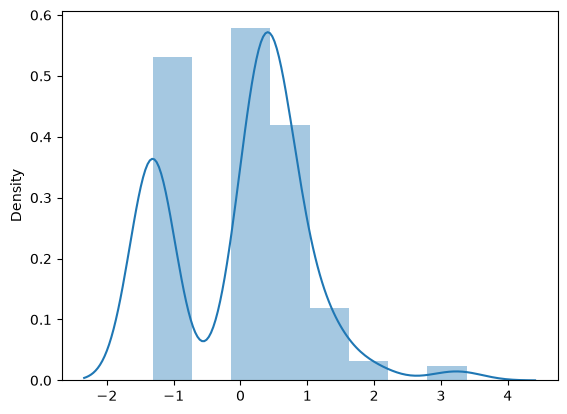

In [11]:
stdNBgraph(dataset["salary"])

What is the probability Density Function of the salary range from
700000 to 900000

In [12]:
def get_pdf_probability(dataset,startrange,endrange):
    from matplotlib import pyplot
    from scipy.stats import norm
    import seaborn as sns
    ax = sns.distplot(dataset,kde=True,kde_kws={'color':'blue'},color='Green')
    pyplot.axvline(startrange,color='Red')
    pyplot.axvline(endrange,color='Red')
    # generate a sample
    sample = dataset
    # calculate parameters
    sample_mean =sample.mean()
    sample_std = sample.std()
    print('Mean=%.3f, Standard Deviation=%.3f' % (sample_mean, sample_std))
    # define the distribution
    dist = norm(sample_mean, sample_std)
    
    # sample probabilities for a range of outcomes
    values = [value for value in range(startrange, endrange)]
    probabilities = [dist.pdf(value) for value in values]    
    prob=sum(probabilities)
    print("The area between range({},{}):{}".format(startrange,endrange,sum(probabilities)))
    return prob

C:\Users\jency\AppData\Local\Temp\ipykernel_6700\132380739.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  ax = sns.distplot(dataset,kde=True,kde_kws={'color':'blue'},color='Green')


Mean=197615.116, Standard Deviation=150305.844
The area between range(700000,900000):0.0004137812663830048


np.float64(0.0004137812663830048)

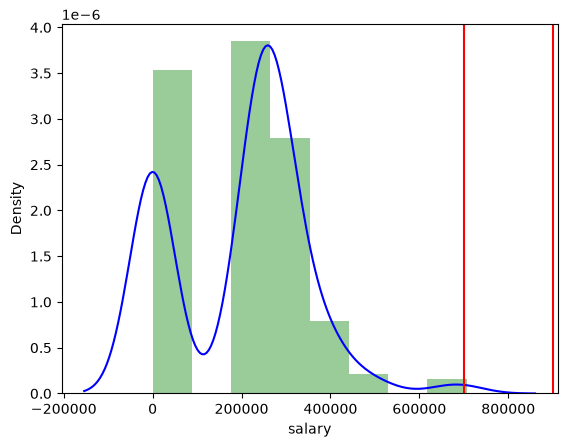

In [15]:
get_pdf_probability(dataset["salary"],700000,900000)

Conclusion: as per the chart and PDF ,The salary between 7 lakhs to 9 lakhs is very less

Test the similarity between the degree_t(Sci&Tech)with respect to
etest_p and mba_p at significance level of 5%.(Make decision using Hy-
pothesis Testing

Dependent Sample
Same Group(degree(scitech) but Different Condition(etest_p,mba_p)

In [16]:
from scipy.stats import ttest_rel
dataset=dataset.dropna()
scitech1 = dataset[dataset['degree_t']=='Sci&Tech']['etest_p']
scitech2 = dataset[dataset['degree_t']=='Sci&Tech']['mba_p']
ttest_rel(scitech1, scitech2)

TtestResult(statistic=np.float64(5.0049844583693615), pvalue=np.float64(5.5179206005054e-06), df=np.int64(58))

H0 Null hypotheses - There is no significant difference in mba and etest pass mark with respect to degree(sci&tech)

H1 Alternate hypotheses - There is a significant difference in mba and etest pass mark with respect to degree(sci&tech)

Conclusion:
Here P value is lesser than 5% so accept null hypothesis , There is no significant diffrence between mba nd etest pass mark with respect to degree sci&tech

Which parameter is highly correlated with salary?

In [23]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calc_vif(X):

    # Calculating VIF
    vif = pd.DataFrame()
    vif["variables"] = X.columns
    vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

    return(vif)

In [22]:
#!pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   -- ------------------------------------- 0.8/11.3 MB 4.3 MB/s eta 0:00:03
   ------ --------------------------------- 1.8/11.3 MB 4.5 MB/s eta 0:00:03
   ----------- ---------------------------- 3.1/11.3 MB 5.2 MB/s eta 0:00:02
   -------------- ------------------------- 4.2/11.3 MB 5.3 MB/s eta 0:00:02
   ------------------- -------------------- 5.5/11.3 MB 5.5 MB/s eta 0:00:02
   ------------------------ --------------- 6.8/11.3 MB 5.6 MB/s eta 0:00:01
   ---------------------------- ----------- 8.1/11.3 MB 5.8 MB/s eta 0:00:01
   --------------------------------- ------ 9.4/11.3 MB 5.8 MB/s eta 0:00:01
   ------------------------------------ --- 10.5/11.3 MB 5.9 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 5.8 MB/s  0:00:01

   ---------------------------------------- 0/5 [wrapt]
   ---------------------------------------- 0/5 [wrapt]
   -------- ------------------------------- 1/5 

In [45]:
data=calc_vif(dataset[["mba_p","salary","ssc_p","hsc_p","degree_p","etest_p"]])

In [46]:
data

,variables,VIF
0,mba_p,1.339867
1,salary,1.627976
2,ssc_p,1.966202
3,hsc_p,1.554751
4,degree_p,1.602162
5,etest_p,1.109549


from this above step ssc pass mark is highly correalted with salary.

conclusion:
ssc has high correlation with salary, indictes moderate positive relationship.

plot any useful graph and explain it

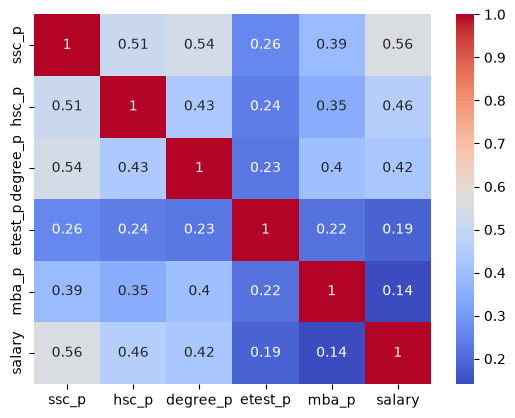

In [44]:
import seaborn as sns
import matplotlib.pyplot as plt
#corr_matrix=[dataset]
data=dataset.drop(columns=["sl_no"]) #drop slno column
corr_matrix=data.corr(numeric_only=True) #use only numeric values

sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")
plt.show()

In this graph correlation heatmap we can find the multicollinearity using correlation
+1 - Perfect Positive relationship
0 - No linear relationship
-1 - Perfect negative relationship
Here Salary and ssc pass mark has highest relationship value(0.56) compare to others.
To find the exact correlation use VIF. 